# Degeneracy counter: $N_c = \dim\ker A$ for a *parametrised* operator on an $L_y \times L_x$ torus over $GF(p)$

Core parameters: the operator (`OP`), the torus (`Lx`, `Ly`), the modulus (`p`). Everything downstream reads them.
$\mathrm{GSD} = p^{N_c}$.

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from math import gcd

## Operators

In [17]:
def stencil_op(shifts, name=None):
    """Operator callable built from a shift list.

    shifts : list of (d_row, d_col) or (d_row, d_col, coeff);  d_row is e_2, d_col is e_1.
    Returns f(t, p) acting on the LAST TWO dims, so it works on a single (Ly, Lx)
    configuration and on a batch (N, Ly, Lx) alike.  torch.roll wraps -> PBC for free.
    """
    terms = [(s[0], s[1], s[2] if len(s) > 2 else 1) for s in shifts]

    def f(t, p=2):
        out = torch.zeros_like(t)
        for (d2, d1, c) in terms:
            out = out + c * torch.roll(t, shifts=(d2, d1), dims=(-2, -1))
        return out % p

    f.terms = terms
    f.name = name or "stencil"
    return f


# Haah model simplified
Z_shifts = [
    (0, 0), (0, 1), (0, 2),   # bottom row: 3 cells
    (1, 0), (1, 1),           # middle row: 2 cells
    (2, 0),                   # top row: 1 cell
]

X_shifts = [(-d2, -d1) for (d2, d1) in Z_shifts]

OPS = {
    # triangular six-neighbour rule: x + 1/x + y + 1/y + y/x + x/y
    "six":       stencil_op([(0, 1), (0, -1), (1, 0), (-1, 0), (-1, 1), (1, -1)], "six"),
    # the CC_Model draft:  t + roll(t, 1, 0) + roll(t, -1, -1)  ==  1 + y + 1/x
    "two_roll":  stencil_op([(0, 0), (1, 0), (0, -1)], "two_roll"),
    # Haah model X
    "haah_z": stencil_op(Z_shifts, "haah_z")
    # Newman-Moore / Sierpinski:  1 + x + y   (mirror image of two_roll -> same N_c)
    # "nm":        stencil_op([(0, 0), (0, 1), (1, 0)], "nm"),
    # square-lattice plus:  x + 1/x + y + 1/y
    # "plus4":     stencil_op([(0, 1), (0, -1), (1, 0), (-1, 0)], "plus4"),
    # coefficients are allowed:  2 + x + y  (identical to nm at p=2, different for p>2)
    # "nm_w2":     stencil_op([(0, 0, 2), (0, 1, 1), (1, 0, 1)], "nm_w2"),
    # 1 + x + y + xy  = (1+x)(1+y)
    # "square4":   stencil_op([(0, 0), (0, 1), (1, 0), (1, 1)], "square4"),
}

print({k: v.terms for k, v in OPS.items()})

{'six': [(0, 1, 1), (0, -1, 1), (1, 0, 1), (-1, 0, 1), (-1, 1, 1), (1, -1, 1)], 'two_roll': [(0, 0, 1), (1, 0, 1), (0, -1, 1)], 'haah_z': [(0, 0, 1), (0, 1, 1), (0, 2, 1), (1, 0, 1), (1, 1, 1), (2, 0, 1)]}


In [18]:
# ---------------- core parameters ----------------
OP = OPS["haah_z"]        # any callable f(t, p) works, not only OPS entries
Lx, Ly, p = 8, 8, 2
LS = range(2, 16)           # sweep range
# -------------------------------------------------
# print(f"OP={OP.name}  terms={OP.term}   Lx={Lx} Ly={Ly} p={p}")

## $GF(p)$ linear algebra

In [19]:
def gfp_inv(a, p):
    """Multiplicative inverse in GF(p) via Fermat. p must be prime."""
    a = int(a) % p
    if a == 0:
        raise ZeroDivisionError("0 has no inverse in GF(p)")
    return pow(a, p - 2, p)


def gfp_rref(M, p=2):
    """Row-reduced echelon form over GF(p). Returns (R, pivot_columns)."""
    M = M.clone() % p
    rows, cols = M.shape
    pivots, r = [], 0
    for col in range(cols):
        piv = None
        for rr in range(r, rows):
            if M[rr, col] != 0:
                piv = rr
                break
        if piv is None:
            continue
        M[[r, piv]] = M[[piv, r]]
        M[r] = (M[r] * gfp_inv(M[r, col], p)) % p
        for rr in range(rows):
            if rr != r and M[rr, col] != 0:
                M[rr] = (M[rr] - M[rr, col] * M[r]) % p
        pivots.append(col)
        r += 1
        if r == rows:
            break
    return M, pivots


def gfp_rank(M, p=2):
    return len(gfp_rref(M, p)[1])


def gfp_nullspace(A, p=2):
    """Basis for {t : A t = 0} over GF(p), one vector per row."""
    R, pivots = gfp_rref(A, p)
    cols = A.shape[1]
    free = [c for c in range(cols) if c not in pivots]
    basis = []
    for f in free:
        v = torch.zeros(cols, dtype=torch.int64)
        v[f] = 1
        for i, pc in enumerate(pivots):
            v[pc] = (-R[i, f]) % p
        basis.append(v)
    return torch.stack(basis) if basis else torch.zeros((0, cols), dtype=torch.int64)


def gfp_rank_fast(M, p=2):
    """Same rank, elimination vectorised as a rank-1 update. Used for the sweeps."""
    M = M.clone() % p
    rows, cols = M.shape
    r = 0
    for col in range(cols):
        nz = (M[r:, col] != 0).nonzero()
        if nz.numel() == 0:
            continue
        piv = r + int(nz[0])
        if piv != r:
            M[[r, piv]] = M[[piv, r]]
        M[r] = (M[r] * gfp_inv(M[r, col], p)) % p
        factors = M[:, col].clone()
        factors[r] = 0
        M = (M - torch.outer(factors, M[r])) % p
        r += 1
        if r == rows:
            break
    return r

In [20]:
def build_matrix(op, Lx, Ly, p=2):
    """Matrix of `op` on an Ly x Lx torus over GF(p): column k = op(delta_k)."""
    N = Lx * Ly
    E = torch.eye(N, dtype=torch.int64).reshape(N, Ly, Lx)   # N stacked deltas
    return (op(E, p).reshape(N, N).T.contiguous()) % p


def build_matrix_slow(op, Lx, Ly, p=2):
    """Readable reference: one delta at a time."""
    N = Lx * Ly
    A = torch.zeros((N, N), dtype=torch.int64)
    for k in range(N):
        e = torch.zeros((Ly, Lx), dtype=torch.int64)
        e[k // Lx, k % Lx] = 1
        A[:, k] = op(e, p).flatten()
    return A


def Nc(op, Lx, Ly, p=2):
    return Lx * Ly - gfp_rank_fast(build_matrix(op, Lx, Ly, p), p)


def gsd(op, Lx, Ly, p=2):
    return p ** Nc(op, Lx, Ly, p)

In [21]:
# builders and rank routines must agree, for every operator
for name, op in OPS.items():
    for (lx, ly, pp) in [(4, 4, 2), (5, 3, 3), (4, 3, 5)]:
        A_f, A_s = build_matrix(op, lx, ly, pp), build_matrix_slow(op, lx, ly, pp)
        assert bool((A_f == A_s).all()), (name, lx, ly, pp, "builders disagree")
        assert gfp_rank(A_s, pp) == gfp_rank_fast(A_f, pp), (name, "rank routines disagree")
print("builders + rank routines agree for all operators")

# known-answer test: the six-neighbour rule at p=2 has N_c = Lx + Ly + gcd(Lx, Ly) - 2
bad = [(a, b) for a in range(2, 9) for b in range(2, 9)
       if Nc(OPS["six"], a, b, 2) != a + b + gcd(a, b) - 2]
assert not bad, bad
print("six @ p=2 reproduces N_c = Lx + Ly + gcd(Lx, Ly) - 2")

# # mirror-image stencils must give the same N_c
# print("two_roll vs nm (mirror):",
#       [Nc(OPS["two_roll"], L, L, 3) == Nc(OPS["nm"], L, L, 3) for L in range(2, 10)])

builders + rank routines agree for all operators
six @ p=2 reproduces N_c = Lx + Ly + gcd(Lx, Ly) - 2


## Validation of the kernel

In [22]:
def validate(op, Lx, Ly, p=2, n_random=8, verbose=True):
    """Four checks on ker A: membership (against the ORIGINAL callable), independence,
    rank-nullity, closure under GF(p) combinations."""
    A = build_matrix(op, Lx, Ly, p)
    K = gfp_nullspace(A, p)
    n = K.shape[0]

    viol = sum(int((op(v.reshape(Ly, Lx), p) != 0).any()) for v in K)
    in_kernel = (viol == 0)
    independent = (gfp_rank(K, p) == n) if n > 0 else True
    rank_nullity = (gfp_rank(A, p) + n == Lx * Ly)

    closed = True
    for _ in range(n_random if n > 0 else 0):
        combo = (torch.randint(0, p, (n,)) @ K) % p
        closed &= bool((op(combo.reshape(Ly, Lx), p) == 0).all())

    ok = in_kernel and independent and rank_nullity and closed
    if verbose:
        print(f"op={op.name:9s} Lx={Lx:2d} Ly={Ly:2d} p={p}: "
              f"N_c={n:3d}  GSD={p}^{n}   in_kernel={in_kernel} ({viol} viol)  "
              f"indep={independent}  rank-nullity={rank_nullity}  closed={closed}  -> {ok}")
    return n, ok

In [23]:
validate(OP, Lx, Ly, p)
print()
for name in OPS:
    for pp in (2, 3, 5):
        assert validate(OPS[name], 5, 4, pp)[1]

op=haah_z    Lx= 8 Ly= 8 p=2: N_c= 15  GSD=2^15   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True

op=six       Lx= 5 Ly= 4 p=2: N_c=  8  GSD=2^8   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=six       Lx= 5 Ly= 4 p=3: N_c=  1  GSD=3^1   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=six       Lx= 5 Ly= 4 p=5: N_c=  0  GSD=5^0   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=two_roll  Lx= 5 Ly= 4 p=2: N_c=  0  GSD=2^0   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=two_roll  Lx= 5 Ly= 4 p=3: N_c=  1  GSD=3^1   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=two_roll  Lx= 5 Ly= 4 p=5: N_c=  1  GSD=5^1   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=haah_z    Lx= 5 Ly= 4 p=2: N_c=  2  GSD=2^2   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True

## Sweep $N_c(L_x, L_y)$

In [24]:
def sweep(op, Ls=LS, p=2):
    Ls = list(Ls)
    return np.array([[Nc(op, lx, ly, p) for lx in Ls] for ly in Ls], dtype=int)


def show_grid(g, Ls, title):
    Ls = list(Ls)
    print(title + "   (rows = Ly, cols = Lx)\n")
    print("     " + "".join(f"{lx:5d}" for lx in Ls))
    for a, ly in enumerate(Ls):
        print(f"{ly:3d}  " + "".join(f"{v:5d}" for v in g[a]))
    print()


grids = {pp: sweep(OP, LS, pp) for pp in (2, 3)}
for pp, g in grids.items():
    show_grid(g, LS, f"N_c for op={OP.name}, p={pp}")

N_c for op=haah_z, p=2   (rows = Ly, cols = Lx)

         2    3    4    5    6    7    8    9   10   11   12   13   14   15
  2      3    2    4    2    3    2    4    2    3    2    4    2    3    2
  3      2    3    2    1    4    1    2    3    2    1    4    1    2    3
  4      4    2    7    2    4    2    8    2    4    2    7    2    4    2
  5      2    1    2    1    2    1    2    1    2    1    2    1    2    9
  6      3    4    4    2    7    2    4    4    3    2    8    2    3    4
  7      2    1    2    1    2    1    2    1    2    1    2    1    2    1
  8      4    2    8    2    4    2   15    2    4    2    8    2    4    2
  9      2    3    2    1    4    1    2    3    2    1    4    1    2    3
 10      3    2    4    2    3    2    4    2    3    2    4    2    3   10
 11      2    1    2    1    2    1    2    1    2    1    2    1    2    1
 12      4    4    7    2    8    2    8    4    4    2   15    2    4    4
 13      2    1    2    1    2    1    

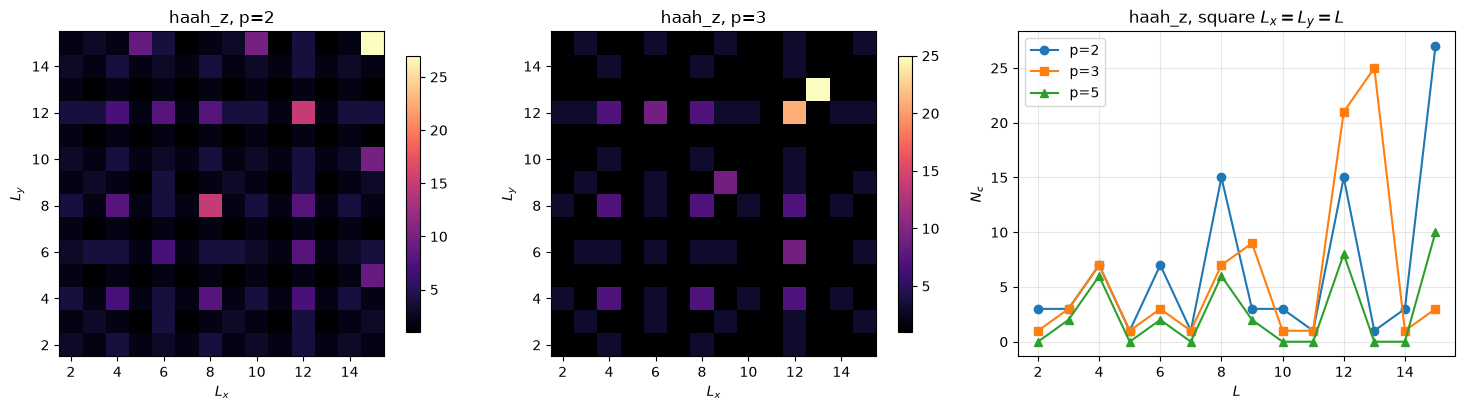

In [25]:
Lsl = list(LS)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for k, pp in enumerate((2, 3)):
    im = ax[k].imshow(grids[pp], cmap="magma", origin="lower",
                      extent=[Lsl[0] - .5, Lsl[-1] + .5, Lsl[0] - .5, Lsl[-1] + .5])
    ax[k].set_xlabel("$L_x$"); ax[k].set_ylabel("$L_y$")
    ax[k].set_title(f"{OP.name}, p={pp}")
    fig.colorbar(im, ax=ax[k], shrink=0.85)

for pp, m in zip((2, 3, 5), ("o-", "s-", "^-")):
    ax[2].plot(Lsl, [Nc(OP, L, L, pp) for L in Lsl], m, label=f"p={pp}")
ax[2].set_xlabel("$L$"); ax[2].set_ylabel("$N_c$")
ax[2].set_title(f"{OP.name}, square $L_x=L_y=L$")
ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Operator $\times$ modulus comparison (square tori)

In [26]:
squares = list(range(2, 13))
table = {}
for name, op in OPS.items():
    for pp in (2, 3, 5):
        table[(name, pp)] = [Nc(op, L, L, pp) for L in squares]

print("N_c for L = " + " ".join(f"{L:3d}" for L in squares) + "\n")
for (name, pp), row in table.items():
    print(f"  {name:9s} p={pp}: " + " ".join(f"{v:3d}" for v in row))

N_c for L =   2   3   4   5   6   7   8   9  10  11  12

  six       p=2:   4   7  10  13  16  19  22  25  28  31  34
  six       p=3:   1   6   1   1   6   1  13  18   1   1   6
  six       p=5:   0   6   0   0   6   0  12   6   0   0   6
  two_roll  p=2:   0   2   0   0   4   6   0   2   0   0   8
  two_roll  p=3:   1   3   1   1   3   1   7   9   1   1   3
  two_roll  p=5:   0   2   3   0   2   0   3   2   0   0   5
  haah_z    p=2:   3   3   7   1   7   1  15   3   3   1  15
  haah_z    p=3:   1   3   7   1   3   1   7   9   1   1  21
  haah_z    p=5:   0   2   6   0   2   0   6   2   0   0   8


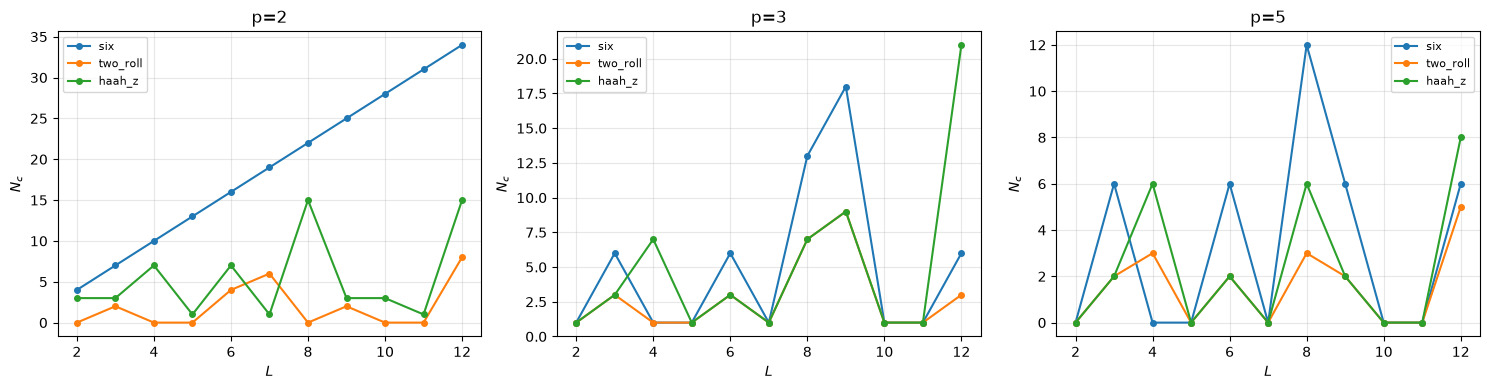

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_, pp in zip(axes, (2, 3, 5)):
    for name in OPS:
        ax_.plot(squares, table[(name, pp)], "o-", markersize=4, label=name)
    ax_.set_xlabel("$L$"); ax_.set_ylabel("$N_c$"); ax_.set_title(f"p={pp}")
    ax_.grid(alpha=0.3); ax_.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Explicit kernel for the current parameters

op=haah_z  Lx=8 Ly=8 p=2  ->  N_c = 15, GSD = 2^15 = 32768

--- v0  (weight 18) ---
[[1 1 0 1 1 0 1 1]
 [0 0 1 0 1 0 0 0]
 [1 0 0 0 0 1 0 0]
 [1 0 0 0 1 0 0 0]
 [0 1 1 0 0 0 0 0]
 [1 0 1 0 0 0 0 0]
 [1 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
--- v1  (weight 24) ---
[[0 0 1 1 0 1 1 0]
 [0 0 1 1 1 1 0 0]
 [1 1 0 0 0 1 1 0]
 [1 1 0 0 1 1 0 0]
 [0 1 0 1 0 0 0 0]
 [1 1 1 1 0 0 0 0]
 [1 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
--- v2  (weight 26) ---
[[1 1 0 0 0 0 0 0]
 [0 0 1 1 0 1 1 0]
 [1 1 1 0 0 1 1 1]
 [1 1 1 0 1 1 1 0]
 [0 1 0 0 1 0 0 0]
 [1 1 0 1 1 0 0 0]
 [1 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
--- v3  (weight 32) ---
[[1 0 1 1 1 0 1 1]
 [0 0 1 1 0 0 1 1]
 [0 1 1 1 0 1 1 1]
 [1 1 1 1 1 1 1 1]
 [0 1 0 0 0 1 0 0]
 [1 1 0 0 1 1 0 0]
 [1 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0 0]]
--- v4  (weight 26) ---
[[0 0 0 0 0 1 1 0]
 [1 0 1 1 0 0 0 1]
 [0 0 1 1 1 1 1 1]
 [0 1 1 1 0 1 1 1]
 [0 1 0 0 0 0 1 0]
 [1 1 0 0 0 1 1 0]
 [1 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0]]
--- v5  (weight 24) ---
[[1 1 0 1 1 0 0 0]
 [1 1 1 1 0 

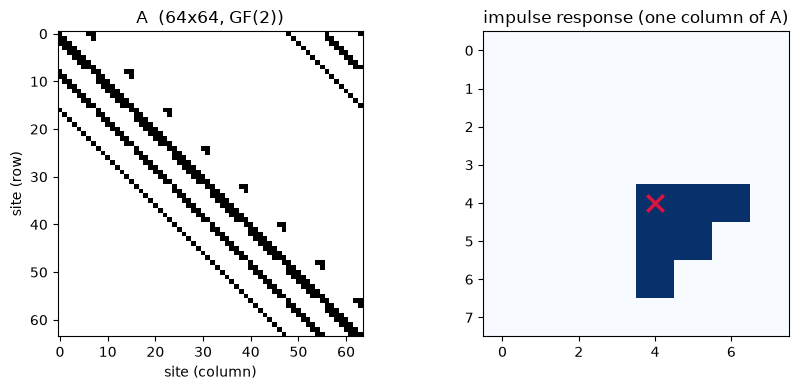

In [28]:
A = build_matrix(OP, Lx, Ly, p)
K = gfp_nullspace(A, p)
print(f"op={OP.name}  Lx={Lx} Ly={Ly} p={p}  ->  N_c = {K.shape[0]}, GSD = {p}^{K.shape[0]} = {p**K.shape[0]}\n")

for idx, v in enumerate(K):
    g = v.reshape(Ly, Lx)
    print(f"--- v{idx}  (weight {int((g != 0).sum())}) ---")
    print(g.numpy())

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(A.numpy(), cmap="Greys", interpolation="nearest")
ax[0].set_title(f"A  ({Lx*Ly}x{Lx*Ly}, GF({p}))")
ax[0].set_xlabel("site (column)"); ax[0].set_ylabel("site (row)")
r = OP(torch.eye(Lx * Ly, dtype=torch.int64).reshape(-1, Ly, Lx), p)[(Ly // 2) * Lx + Lx // 2]
ax[1].imshow(r.numpy(), cmap="Blues", vmin=0, vmax=max(1, p - 1))
ax[1].scatter([Lx // 2], [Ly // 2], marker="x", s=140, c="crimson", linewidths=2.5)
ax[1].set_title("impulse response (one column of A)")
plt.tight_layout(); plt.show()

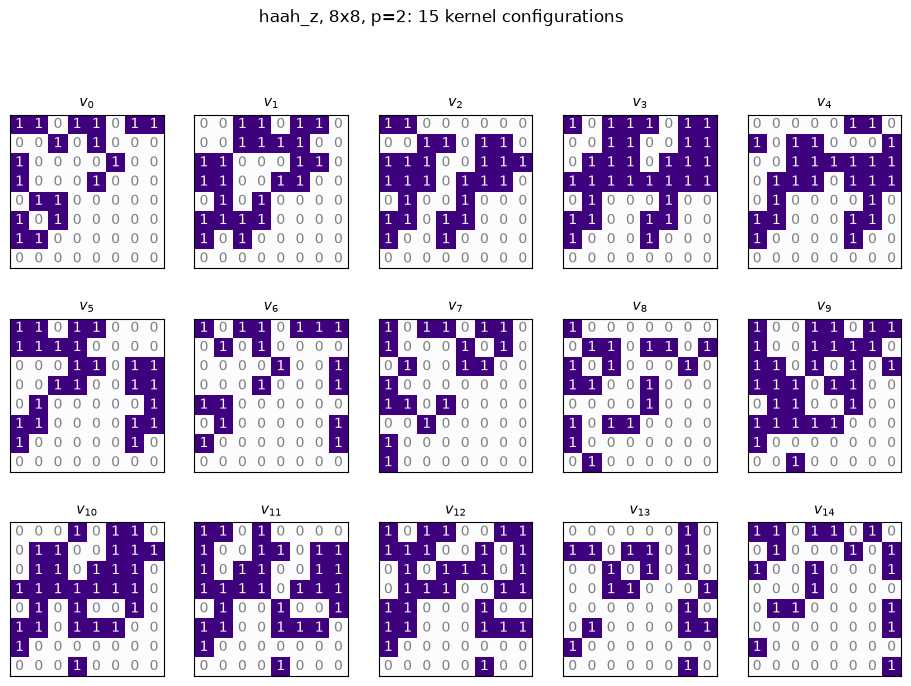

In [29]:
n = K.shape[0]
if n:
    ncols = min(5, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.3 * ncols, 2.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for idx, ax_ in enumerate(axes):
        if idx < n:
            g = K[idx].reshape(Ly, Lx).numpy()
            ax_.imshow(g, cmap="Purples", vmin=0, vmax=max(1, p - 1))
            for i in range(Ly):
                for j in range(Lx):
                    ax_.text(j, i, g[i, j], ha="center", va="center",
                             color="white" if g[i, j] else "gray", fontsize=10)
            ax_.set_title(f"$v_{{{idx}}}$", fontsize=10)
        ax_.set_xticks([]); ax_.set_yticks([])
        if idx >= n:
            ax_.axis("off")
    fig.suptitle(f"{OP.name}, {Ly}x{Lx}, p={p}: {n} kernel configurations", y=1.01)
    plt.show()
else:
    print("empty kernel")

## Custom operator: any `f(t, p)` acting on the last two dims

In [30]:
def my_op(t, p=2):
    """Example hand-written rule: t + roll(t, 1, rows) + roll(t, -1, cols) + roll(t, (2, 2))."""
    return (t
            + torch.roll(t, 1, -2)
            + torch.roll(t, -1, -1)
            + torch.roll(t, shifts=(2, 2), dims=(-2, -1))) % p


my_op.name = "my_op"
my_op.terms = "custom"

for pp in (2, 3):
    validate(my_op, 6, 4, pp)
print()
print("N_c(L, L) for my_op:", {pp: [Nc(my_op, L, L, pp) for L in range(2, 13)] for pp in (2, 3)})

op=my_op     Lx= 6 Ly= 4 p=2: N_c=  6  GSD=2^6   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True
op=my_op     Lx= 6 Ly= 4 p=3: N_c=  3  GSD=3^3   in_kernel=True (0 viol)  indep=True  rank-nullity=True  closed=True  -> True

N_c(L, L) for my_op: {2: [2, 5, 4, 5, 10, 13, 8, 11, 10, 11, 20], 3: [1, 0, 1, 0, 3, 0, 5, 0, 1, 0, 3]}
